# Download Dataset

In [ ]:
!pip install roboflow

from roboflow import Roboflow

# Initialize Roboflow with the provided API key
rf = Roboflow(api_key="YOUR ROBOFLOW API KEY")
project = rf.workspace("personal-protective-equipment").project("ppes-kaxsi")

version = project.version(8)

dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 115.2 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PPEs-8 in yolov8:: 100%|██████████| 49860/49860 [00:09<00:00, 5442.83it/s]


# Checking class labels

In [ ]:
import os

BASE = "PPEs-8"
splits = ["train", "valid", "test"]
TARGET_CLASSES = {0, 5}

results = {0: [], 5: []}

for split in splits:
    label_dir = os.path.join(BASE, split, "labels")

    for lbl_file in os.listdir(label_dir):
        lbl_path = os.path.join(label_dir, lbl_file)

        with open(lbl_path) as f:
            for line in f:
                cls = int(line.strip().split()[0])
                if cls in TARGET_CLASSES:
                    results[cls].append((split, lbl_file))
                    break  # no need to read rest of file


In [ ]:
for cls_id, files in results.items():
    print(f"\nClass {cls_id} found in {len(files)} label files")
    print("Sample files:")
    for item in files[:5]:
        print(" ", item)



Class 0 found in 3223 label files
Sample files:
  ('train', 'img210_jpg.rf.681c4dfbe4ed6ac262bed35ab3924bf3.txt')
  ('train', 'img11_jpg.rf.634f888eb1b064369d3e38313f5c85ef.txt')
  ('train', 'PP02img240_jpg.rf.045dcff8961bb77be02a4ff104836f3e.txt')
  ('train', 'img162_jpg.rf.bb2af0e05e52f8d9c4464b143c297175.txt')
  ('train', 'img441_jpg.rf.fa5cca94a3af6ae6c402ad729d9495ea.txt')

Class 5 found in 4643 label files
Sample files:
  ('train', 'nglovpp2104_jpg.rf.c85498804e7d61ca5ef2517c9d0e4961.txt')
  ('train', 'nglovpp335_jpg.rf.42f1a3c47f60fa6fd6c19701a075b478.txt')
  ('train', 'PP02img855_jpg.rf.a2165c773062641da8e805a0d613fa51.txt')
  ('train', 'PP02img862_jpg.rf.cc7190a4e424d6650d7c3b810bc2dde8.txt')
  ('train', 'nglov105_jpg.rf.f95e6c63be87fa3d3671fa16557f1fb0.txt')


In [ ]:
sample_0 = results[0][0]  # glove candidate
sample_5 = results[5][0]  # no_glove candidate

print("Class 0 sample:", sample_0)
print("Class 5 sample:", sample_5)

Class 0 sample: ('train', 'img210_jpg.rf.681c4dfbe4ed6ac262bed35ab3924bf3.txt')
Class 5 sample: ('train', 'nglovpp2104_jpg.rf.c85498804e7d61ca5ef2517c9d0e4961.txt')


In [ ]:
import cv2
import matplotlib.pyplot as plt

def show_image_with_boxes(split, label_file):
    img_path = os.path.join(BASE, split, "images", label_file.replace(".txt", ".jpg"))
    lbl_path = os.path.join(BASE, split, "labels", label_file)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    with open(lbl_path) as f:
        for line in f:
            cls, xc, yc, bw, bh = map(float, line.split())
            if int(cls) in {0, 5}:
                x1 = int((xc - bw/2) * w)
                y1 = int((yc - bh/2) * h)
                x2 = int((xc + bw/2) * w)
                y2 = int((yc + bh/2) * h)

                color = (0, 255, 0) if int(cls) == 0 else (255, 0, 0)
                label = "gloved_hand" if int(cls) == 0 else "bare_hand"
                cv2.rectangle(img, (x1,y1), (x2,y2), color, 2)
                cv2.putText(img, label, (x1, y1-5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()


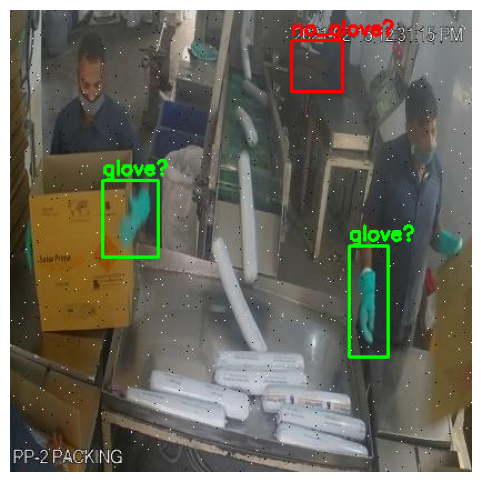

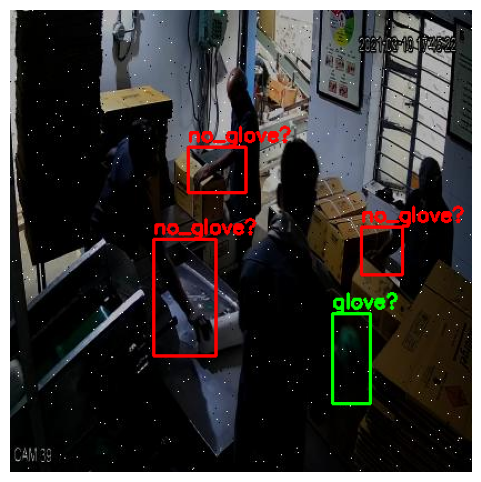

In [ ]:
show_image_with_boxes(*sample_0)
show_image_with_boxes(*sample_5)

# Split Wise Summary

In [ ]:
import os
from collections import defaultdict

BASE = "PPEs-8"
splits = ["train", "valid", "test"]
TARGET_CLASSES = {0, 5}

# results[class_id][split] = list of label files
results = {cls: defaultdict(list) for cls in TARGET_CLASSES}

for split in splits:
    label_dir = os.path.join(BASE, split, "labels")

    for lbl_file in os.listdir(label_dir):
        lbl_path = os.path.join(label_dir, lbl_file)

        with open(lbl_path) as f:
            for line in f:
                cls = int(line.strip().split()[0])
                if cls in TARGET_CLASSES:
                    results[cls][split].append(lbl_file)
                    break  # stop reading this file once found


In [ ]:
for cls_id, split_data in results.items():
    print(f"\nClass {cls_id}:")
    for split in splits:
        count = len(split_data[split])
        print(f"  {split}: {count} label files")



Class 0:
  train: 2944 label files
  valid: 279 label files
  test: 0 label files

Class 5:
  train: 4040 label files
  valid: 603 label files
  test: 0 label files


In [ ]:
for cls_id, split_data in results.items():
    print(f"\nClass {cls_id} sample files:")
    for split in splits:
        files = split_data[split][:3]
        if files:
            for f in files:
                print(f"  {split}/{f}")



Class 0 sample files:
  train/img210_jpg.rf.681c4dfbe4ed6ac262bed35ab3924bf3.txt
  train/img11_jpg.rf.634f888eb1b064369d3e38313f5c85ef.txt
  train/PP02img240_jpg.rf.045dcff8961bb77be02a4ff104836f3e.txt
  valid/fglov1157_jpg.rf.500ef21fb9037480f401b4b5608807b5.txt
  valid/img128_jpg.rf.4f71438cd33d30524b761746d096c452.txt
  valid/goggle87658_jpg.rf.3b02e5baad9e969eba2d89ec82a3c4ae.txt

Class 5 sample files:
  train/nglovpp2104_jpg.rf.c85498804e7d61ca5ef2517c9d0e4961.txt
  train/nglovpp335_jpg.rf.42f1a3c47f60fa6fd6c19701a075b478.txt
  train/PP02img855_jpg.rf.a2165c773062641da8e805a0d613fa51.txt
  valid/frame2875_jpg.rf.2c46c6b727c0f31d841910d4d921135a.txt
  valid/PP02img561_jpg.rf.9e88b8111456abcd99385c1178152fd0.txt
  valid/frame3788_jpg.rf.48af890ccf64899c37bc2d6e7d5bb739.txt


# Filtering

In [ ]:
import os
import shutil

# Paths
SRC_ROOT = "PPEs-8"
DST_ROOT = "glove_only"

# Only keep train and valid (test has no glove samples)
SPLITS = ["train", "valid"]

# Keep + remap classes
# old_id -> new_id
KEEP_CLASSES = {
    0: 0,  # glove
    5: 1   # no_glove
}

# Create output directory structure
for split in SPLITS:
    os.makedirs(f"{DST_ROOT}/{split}/images", exist_ok=True)
    os.makedirs(f"{DST_ROOT}/{split}/labels", exist_ok=True)

# Counters (for sanity check)
stats = {
    "images_kept": 0,
    "labels_written": 0
}

for split in SPLITS:
    img_dir = os.path.join(SRC_ROOT, split, "images")
    lbl_dir = os.path.join(SRC_ROOT, split, "labels")

    for lbl_file in os.listdir(lbl_dir):
        lbl_path = os.path.join(lbl_dir, lbl_file)

        with open(lbl_path, "r") as f:
            lines = f.readlines()

        new_lines = []

        for line in lines:
            parts = line.strip().split()
            cls_id = int(parts[0])

            if cls_id in KEEP_CLASSES:
                new_cls = KEEP_CLASSES[cls_id]
                new_lines.append(
                    f"{new_cls} " + " ".join(parts[1:]) + "\n"
                )

        # If at least one glove / no_glove box exists, keep the image
        if new_lines:
            img_name = lbl_file.replace(".txt", ".jpg")
            src_img = os.path.join(img_dir, img_name)

            # Some images may be .png
            if not os.path.exists(src_img):
                src_img = src_img.replace(".jpg", ".png")

            if not os.path.exists(src_img):
                continue  # skip if image not found

            # Copy image
            shutil.copy(
                src_img,
                f"{DST_ROOT}/{split}/images/{os.path.basename(src_img)}"
            )

            # Write new label file
            with open(f"{DST_ROOT}/{split}/labels/{lbl_file}", "w") as f:
                f.writelines(new_lines)

            stats["images_kept"] += 1
            stats["labels_written"] += len(new_lines)

print("Filtering complete.")
print(stats)

Filtering complete.
{'images_kept': 7866, 'labels_written': 27148}


## Saving the filtered dataset

In [ ]:
!zip -r glove_only.zip glove_only

Streaming output truncated to the last 5000 lines.
  adding: glove_only/train/labels/PP02img893_jpg.rf.6375dd9e9478875df146c58b21752de7.txt (deflated 39%)
  adding: glove_only/train/labels/PP02img955_jpg.rf.fe29f20e31c567732d441123545d3f5e.txt (deflated 47%)
  adding: glove_only/train/labels/nglov122_jpg.rf.9a157e5f4808db9f1b99363bcb7504f7.txt (deflated 57%)
  adding: glove_only/train/labels/PP02img1240_jpg.rf.6ade660358dc1734a8566688b17ce50b.txt (deflated 63%)
  adding: glove_only/train/labels/PP02img174_jpg.rf.51f4b2177d4fd4ee5cdb3f1878458e53.txt (deflated 59%)
  adding: glove_only/train/labels/nglov108_jpg.rf.fee10233dfcf814dac11482368bfae3e.txt (deflated 59%)
  adding: glove_only/train/labels/fglov1122_jpg.rf.84388cab28f0eb3689db7761d2b5b6f8.txt (deflated 57%)
  adding: glove_only/train/labels/nglovpp217_jpg.rf.0ef2c5e96320a617f32654db07b1f38b.txt (deflated 61%)
  adding: glove_only/train/labels/img439_jpg.rf.05068b56f7a51772d633a51330360fe8.txt (deflated 58%)
  adding: glove_only/

# Check labels of filtered dataset

In [ ]:
import os
import random

IMG_DIR = "glove_only/train/images"
LBL_DIR = "glove_only/train/labels"

image_file = random.choice(os.listdir(IMG_DIR))
label_file = image_file.replace(".jpg", ".txt").replace(".png", ".txt")

print("Image:", image_file)
print("Label:", label_file)


Image: img342_jpg.rf.5f26bbb6e61544b312a30286a6458b94.jpg
Label: img342_jpg.rf.5f26bbb6e61544b312a30286a6458b94.txt


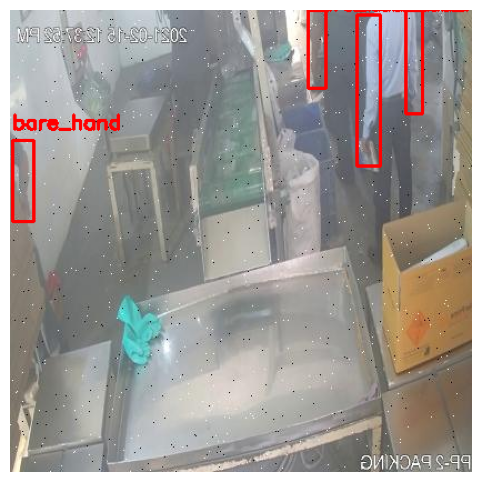

In [ ]:
import cv2
import matplotlib.pyplot as plt

CLASS_NAMES = {
    0: "gloved_hand",
    1: "bare_hand"
}

img_path = os.path.join(IMG_DIR, image_file)
lbl_path = os.path.join(LBL_DIR, label_file)

# Load image
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w, _ = img.shape

# Load labels
with open(lbl_path) as f:
    lines = f.readlines()

for line in lines:
    cls, xc, yc, bw, bh = map(float, line.split())
    cls = int(cls)

    # Convert YOLO -> pixel coordinates
    x1 = int((xc - bw / 2) * w)
    y1 = int((yc - bh / 2) * h)
    x2 = int((xc + bw / 2) * w)
    y2 = int((yc + bh / 2) * h)

    color = (0, 255, 0) if cls == 0 else (255, 0, 0)
    label = CLASS_NAMES[cls]

    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    cv2.putText(
        img,
        label,
        (x1, max(y1 - 10, 0)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        color,
        2
    )

# Show image
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.show()


# Fine Tuning

## Loading Dataset

In [ ]:
!unzip glove_only.zip

Streaming output truncated to the last 5000 lines.
  inflating: glove_only/train/labels/PP02img893_jpg.rf.6375dd9e9478875df146c58b21752de7.txt  
  inflating: glove_only/train/labels/PP02img955_jpg.rf.fe29f20e31c567732d441123545d3f5e.txt  
  inflating: glove_only/train/labels/nglov122_jpg.rf.9a157e5f4808db9f1b99363bcb7504f7.txt  
  inflating: glove_only/train/labels/PP02img1240_jpg.rf.6ade660358dc1734a8566688b17ce50b.txt  
  inflating: glove_only/train/labels/PP02img174_jpg.rf.51f4b2177d4fd4ee5cdb3f1878458e53.txt  
  inflating: glove_only/train/labels/nglov108_jpg.rf.fee10233dfcf814dac11482368bfae3e.txt  
  inflating: glove_only/train/labels/fglov1122_jpg.rf.84388cab28f0eb3689db7761d2b5b6f8.txt  
  inflating: glove_only/train/labels/nglovpp217_jpg.rf.0ef2c5e96320a617f32654db07b1f38b.txt  
  inflating: glove_only/train/labels/img439_jpg.rf.05068b56f7a51772d633a51330360fe8.txt  
  inflating: glove_only/train/labels/nglov174_jpg.rf.853a1c250c60885384695b3366803956.txt  
  inflating: glove_

## Installing YOLOv8 model

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 71.4 MB/s eta 0:00:00


In [ ]:
!yolo version

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
8.3.252


## Data Sanity Check

In [ ]:
from pathlib import Path

labels = list(Path("glove_only").rglob("labels/*.txt"))
assert labels, "❌ No label files found!"

for lbl in labels:
    for line in lbl.read_text().splitlines():
        cls, x, y, w, h = map(float, line.split())
        assert cls in [0, 1], f"Invalid class {cls} in {lbl}"
        for v in (x, y, w, h):
            assert 0.0 <= v <= 1.0, f"Unnormalized value in {lbl}"

print("✅ Dataset sanity check passed")

✅ Dataset sanity check passed


## Fine Tuning Code

In [ ]:
!yolo detect train \
  model=yolov8s.pt \
  data=glove_only/data.yaml \
  epochs=50 \
  imgsz=640 \
  batch=16 \
  name=glove_yolov8_colab

Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=glove_only/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=glove_yolov8_colab, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, p

## Inference on Validation Set

In [ ]:
!yolo detect predict \
  model=runs/detect/glove_yolov8_colab/weights/best.pt \
  source=glove_only/valid/images \
  conf=0.25 \
  save=True


Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs

image 1/882 /content/glove_only/valid/images/NVR-09_Trim_new_Trim-0664_jpg.rf.468aa37a88b25b16b1c0d332065037ea.jpg: 640x640 2 bare_hands, 16.3ms
image 2/882 /content/glove_only/valid/images/NVR-09_Trim_new_Trim-0665_jpg.rf.bcdd9ef7baeb32e136ee9907d788f3ee.jpg: 640x640 2 bare_hands, 16.3ms
image 3/882 /content/glove_only/valid/images/NVR-09_Trim_new_Trim-0669_jpg.rf.d905ed4b14e7b3666dc2b48a719f9837.jpg: 640x640 2 bare_hands, 16.2ms
image 4/882 /content/glove_only/valid/images/NVR-09_Trim_new_Trim-0670_jpg.rf.89bcd6bd02eafc55b474d997a06231c8.jpg: 640x640 2 bare_hands, 16.2ms
image 5/882 /content/glove_only/valid/images/NVR-09_Trim_new_Trim-0671_jpg.rf.1bc0f236bd93111ae1c40b7b9504dea2.jpg: 640x640 2 bare_hands, 16.2ms
image 6/882 /content/glove_only/valid/images/NVR-09_Trim_new_Trim-0868_jpg.rf.041d9bb6a96cdbf6cb2a7ea2629e601

## Metrics

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import json

model = YOLO("runs/detect/glove_yolov8_colab/weights/best.pt")

image_dir = Path("glove_only/valid/images")
log_dir = Path("logs")
log_dir.mkdir(exist_ok=True)

for img_path in image_dir.glob("*.jpg"):
    results = model(img_path, conf=0.25)[0]

    detections = []
    for box in results.boxes:
        detections.append({
            "label": model.names[int(box.cls)],
            "confidence": float(box.conf),
            "bbox": box.xyxy[0].tolist()
        })

    output = {
        "filename": img_path.name,
        "detections": detections
    }

    with open(log_dir / f"{img_path.stem}.json", "w") as f:
        json.dump(output, f, indent=2)



image 1/1 /content/glove_only/valid/images/frame3822_jpg.rf.bcf3f36e41e13c45bd9600a6404b6a71.jpg: 640x640 (no detections), 8.2ms
Speed: 3.4ms preprocess, 8.2ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/glove_only/valid/images/frame3750_jpg.rf.5e0d16d616cf299cba8b91fbae7b5366.jpg: 640x640 (no detections), 7.7ms
Speed: 2.4ms preprocess, 7.7ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/glove_only/valid/images/frame1324_jpg.rf.969257e91219a5ad210a9f4eca6a5199.jpg: 640x640 2 bare_hands, 8.2ms
Speed: 2.7ms preprocess, 8.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/glove_only/valid/images/frame148--2-_jpg.rf.744787b5d85cee4052995c92aea288d6.jpg: 640x640 1 bare_hand, 8.3ms
Speed: 2.2ms preprocess, 8.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/glove_only/valid/images/PP02img558_jpg.rf.6d2f278ce0f649e3d098a5a7c16743c2.jpg: 

## Saving Model and result on google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!cp -r runs/detect/glove_yolov8_colab /content/drive/MyDrive/yolov8_glove_model_50epoch